# CycleGAN for Domain Alignment (2D Toy Example)

**Pablo Martínez Olmos, Vanessa Gómez Verdejo,  Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='https://upload.wikimedia.org/wikipedia/commons/8/88/Acronimo_nombre3l.jpg' width=300 />



This notebook demonstrates how to use a CycleGAN to align two 2D domains (toy example) using simple MLPs. The domains are generated by transforming a 2D Gaussian distribution.

---

## SECTION 1: Data Generation
We generate two domains:
- **Domain 1**: Samples from a 2D Gaussian.
- **Domain 2**: Nonlinear transformation (affine + cubic) of Domain 1.

---

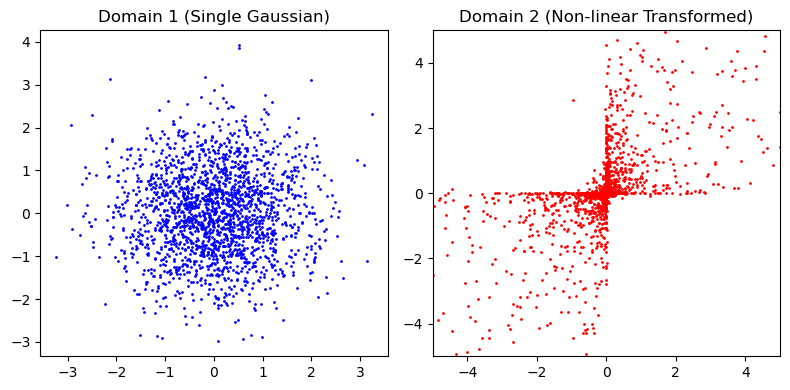

In [ ]:
# CycleGAN for Domain Alignment (2D Toy Example)
# -----------------------------------------------------

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np
import itertools

# DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SECTION 1: Generate 2D Gaussian for Domain 1 and transform to Domain 2
np.random.seed(42)
torch.manual_seed(42)

# Sample from a single 2D Gaussian
def sample_gaussian(n_samples=2000, mean=[0, 0], cov=[[1, 0], [0, 1]]):
    return np.random.multivariate_normal(mean, cov, size=n_samples)


# Apply a simple affine transformation: y = A x + b
def affine_transform(x):
    # Construct a matrix with strong correlation
    # For example: diagonal terms ~1, off-diagonal terms ~0.9
    A = np.array([[1.5, 0.6],
                  [0.6, 0.9]])
    
    # Optionally normalize to avoid exploding scale
    A = A / np.linalg.norm(A, axis=1, keepdims=True)

    b = np.random.randn(1, 2) * 0.2  # Small random bias
    return x @ A.T + b


def rotation_matrix_45_deg():
    theta = np.pi / 4  # 45 degrees in radians
    R = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])
    return R

# Generate source and target domain data
data1_np = sample_gaussian()
data2_np = (affine_transform(data1_np))**3

# Visualize
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.scatter(data1_np[:, 0], data1_np[:, 1], s=1, color='blue')
plt.title("Domain 1 (Single Gaussian)")

plt.subplot(1, 2, 2)
plt.scatter(data2_np[:, 0], data2_np[:, 1], s=1, color='red')
plt.title("Domain 2 (Non-linear Transformed)")
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.tight_layout()
plt.show()


## SECTION 2: Data Preparation
Convert the generated numpy arrays to PyTorch tensors and create DataLoaders for batching.


In [39]:

# Convert to PyTorch
X = torch.tensor(data1_np, dtype=torch.float32)
Y = torch.tensor(data2_np, dtype=torch.float32)
loader_X = DataLoader(TensorDataset(X), batch_size=128, shuffle=True)
loader_Y = DataLoader(TensorDataset(Y), batch_size=128, shuffle=True)



## SECTION 3: Model Definitions, Losses and Optimizers
Define simple MLP-based generators and discriminators for both domains. Set up the loss functions (Wasserstein, cycle consistency, identity) and optimizers for the generators and discriminators.


In [47]:
# SECTION 2: Small MLP Generator/Discriminator
class MLPGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 5), nn.Tanh(),
            nn.Linear(5, 10), nn.Tanh(),
            nn.Linear(10, 5), nn.Tanh(),
            nn.Linear(5, 5), nn.Tanh(),
            nn.Linear(5, 2)
        )

    def forward(self, x):
        return self.net(x)

class MLPDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 10), nn.ReLU(),
            nn.Linear(10, 5), nn.ReLU(),
            nn.Linear(5, 1)  # No sigmoid for WGAN
        )

    def forward(self, x):
        return self.net(x)

G_XtoY = MLPGenerator().to(device)
G_YtoX = MLPGenerator().to(device)
D_X = MLPDiscriminator().to(device)
D_Y = MLPDiscriminator().to(device)

# SECTION 3: Losses and Optimizers
cycle_criterion = nn.L1Loss()
identity_criterion = nn.L1Loss()

g_params = itertools.chain(G_XtoY.parameters(), G_YtoX.parameters())
optimizer_G = optim.RMSprop(g_params, lr=0.005)
optimizer_D_X = optim.RMSprop(D_X.parameters(), lr=0.005)
optimizer_D_Y = optim.RMSprop(D_Y.parameters(), lr=0.005)

---

## SECTION 4: Training Loop

---

In [48]:
# SECTION 4: Training
EPOCHS = 100
clip_value = 0.2
critic_iters = 10

# Initialize loss logs
losses_G = []
losses_D_X = []
losses_D_Y = []
losses_cycle = []
losses_identity = []

for epoch in range(EPOCHS):
    for (x_batch,), (y_batch,) in zip(loader_X, loader_Y):
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        # ----------------------
        #  Train Discriminators
        # ----------------------
        for _ in range(critic_iters):
            # Discriminator X
            optimizer_D_X.zero_grad()
            fake_X = G_YtoX(y_batch).detach()
            loss_D_X = -torch.mean(D_X(x_batch)) + torch.mean(D_X(fake_X))
            loss_D_X.backward()
            optimizer_D_X.step()
            for p in D_X.parameters():
                p.data.clamp_(-clip_value, clip_value)

            # Discriminator Y
            optimizer_D_Y.zero_grad()
            fake_Y = G_XtoY(x_batch).detach()
            loss_D_Y = -torch.mean(D_Y(y_batch)) + torch.mean(D_Y(fake_Y))
            loss_D_Y.backward()
            optimizer_D_Y.step()
            for p in D_Y.parameters():
                p.data.clamp_(-clip_value, clip_value)

        # ----------------------
        #  Train Generators
        # ----------------------
        optimizer_G.zero_grad()
        fake_Y = G_XtoY(x_batch)
        fake_X = G_YtoX(y_batch)

        loss_G_XtoY = -torch.mean(D_Y(fake_Y))
        loss_G_YtoX = -torch.mean(D_X(fake_X))

        recov_X = G_YtoX(fake_Y)
        recov_Y = G_XtoY(fake_X)
        loss_cycle = cycle_criterion(recov_X, x_batch) + cycle_criterion(recov_Y, y_batch)

        same_X = G_YtoX(x_batch)
        same_Y = G_XtoY(y_batch)
        loss_identity = identity_criterion(same_X, x_batch) + identity_criterion(same_Y, y_batch)

        loss_G = loss_G_XtoY + loss_G_YtoX + 1.0 * loss_cycle + 1.0 * loss_identity
        loss_G.backward()
        optimizer_G.step()

        # Log losses
        losses_G.append(loss_G.item())
        losses_D_X.append(loss_D_X.item())
        losses_D_Y.append(loss_D_Y.item())
        losses_cycle.append(loss_cycle.item())
        losses_identity.append(loss_identity.item())

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}: G={loss_G.item():.4f}, D_X={loss_D_X.item():.4f}, D_Y={loss_D_Y.item():.4f}")


Epoch 5: G=2.5106, D_X=-0.0556, D_Y=-0.2094
Epoch 10: G=2.0671, D_X=-0.0715, D_Y=-0.1598
Epoch 15: G=1.3371, D_X=-0.0624, D_Y=-0.1446
Epoch 20: G=3.3505, D_X=-0.0690, D_Y=-0.3709
Epoch 25: G=2.0664, D_X=-0.0619, D_Y=-0.2412
Epoch 30: G=1.8538, D_X=-0.0554, D_Y=-0.2988
Epoch 35: G=1.5764, D_X=-0.0597, D_Y=-0.2518
Epoch 40: G=1.9423, D_X=-0.0456, D_Y=-0.2983
Epoch 45: G=1.9182, D_X=-0.0638, D_Y=-0.2537
Epoch 50: G=2.0364, D_X=-0.0551, D_Y=-0.3464
Epoch 55: G=2.1996, D_X=-0.0577, D_Y=-0.3033
Epoch 60: G=1.3077, D_X=-0.0703, D_Y=-0.1181
Epoch 65: G=1.4085, D_X=-0.0446, D_Y=-0.1953
Epoch 70: G=2.0903, D_X=-0.0718, D_Y=-0.2519
Epoch 75: G=2.4152, D_X=-0.0589, D_Y=-0.3409
Epoch 80: G=2.1818, D_X=-0.0702, D_Y=-0.3677
Epoch 85: G=1.5017, D_X=-0.1009, D_Y=-0.2761
Epoch 90: G=1.5663, D_X=-0.0665, D_Y=-0.2778
Epoch 95: G=1.8891, D_X=-0.0734, D_Y=-0.3382
Epoch 100: G=1.1233, D_X=-0.0564, D_Y=-0.2506


---

## SECTION 5: Plot Loss Curves
Visualize the evolution of generator, discriminator, cycle, and identity losses during training.

---

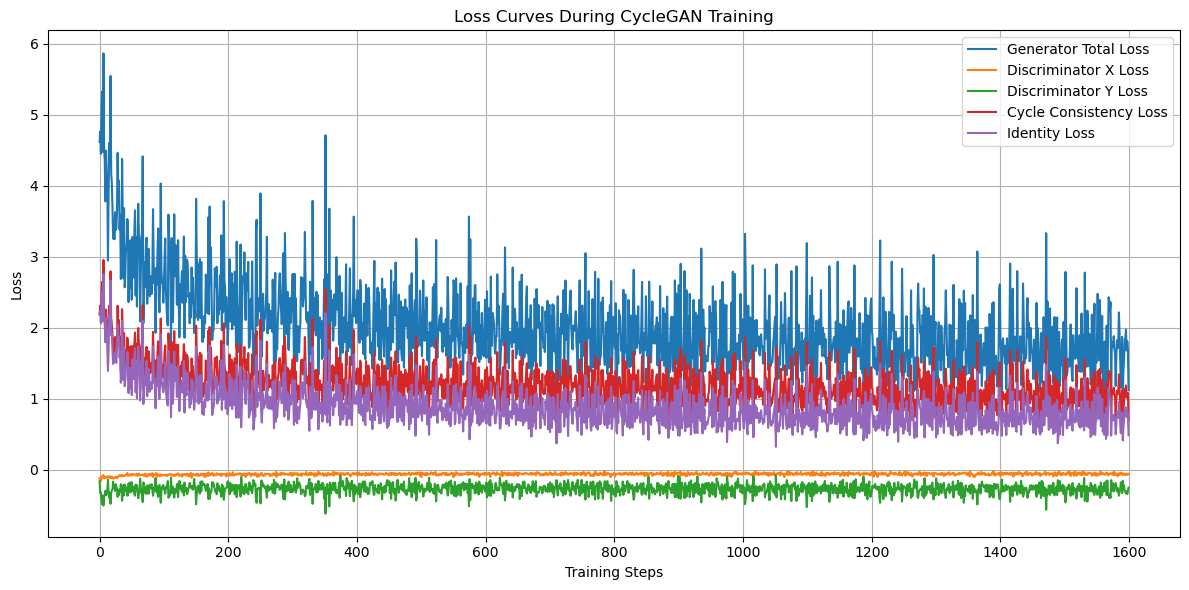

In [51]:
# SECTION 6: Plot Loss Curves
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(losses_G, label='Generator Total Loss')
plt.plot(losses_D_X, label='Discriminator X Loss')
plt.plot(losses_cycle, label='Cycle Consistency Loss')
plt.plot(losses_D_Y, label='Discriminator Y Loss')
plt.plot(losses_identity, label='Identity Loss')

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Loss Curves During CycleGAN Training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



## SECTION 6: Visualize Domain Mapping
Plot the original and mapped samples to visually assess the quality of the learned mappings between domains.

---

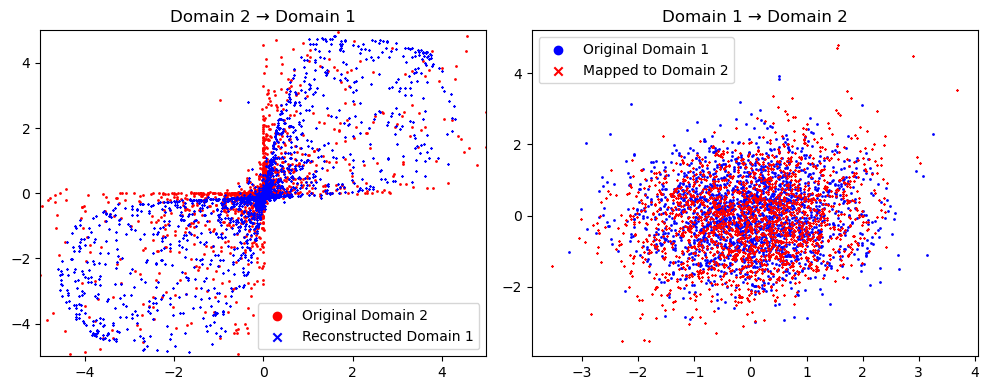

In [53]:
# SECTION 5: Visualize Mapping (for single Gaussian)
with torch.no_grad():
    fake_Y_full = G_XtoY(torch.tensor(data1_np, dtype=torch.float32).to(device)).cpu().numpy()
    recov_X_full = G_YtoX(torch.tensor(data2_np, dtype=torch.float32).to(device)).cpu().numpy()

plt.figure(figsize=(10, 4))

# Domain 2 → Domain 1
plt.subplot(1, 2, 1)
plt.scatter(data2_np[:, 0], data2_np[:, 1], s=1, color='red', label='Original Domain 2')
plt.scatter(recov_X_full[:, 0], recov_X_full[:, 1], s=1, color='blue', marker='x', label='Reconstructed Domain 1')
plt.title("Domain 2 → Domain 1")
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.legend(markerscale=6)

# Domain 1 → Domain 2
plt.subplot(1, 2, 2)
plt.scatter(data1_np[:, 0], data1_np[:, 1], s=1, color='blue', label='Original Domain 1')
plt.scatter(fake_Y_full[:, 0], fake_Y_full[:, 1], s=1, color='red', marker='x', label='Mapped to Domain 2')
plt.title("Domain 1 → Domain 2")
plt.legend(markerscale=6)

plt.tight_layout()
plt.show()
